In [27]:
# Murilo Patricio Maia
# Alice Martins Valero
# Beatriz Santos de Oliveira

import pandas as pd
import matplotlib.pyplot as plt
import random
import time

def limpa(string: str):
    qtd = 0
    palavra = ""
    for char in string:
        if qtd >= 2:
            palavra += char
        elif char == " ":
            qtd+=1

    return palavra

Atividade 2 - Recuperação e exploração inicial da base de dados

In [28]:

df = pd.read_csv(".\\dataset\\ALUNOS-COM-DEFICIENCIA-2021.csv", sep=";", encoding="utf_8")

# PAra entender a estrutura (metadados) dos dados
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   1.1 - Matricula               415 non-null    object
 1   1.2 - Campus                  415 non-null    object
 2   1.4 - Ano                     415 non-null    int64 
 3   2.1 - PcD                     415 non-null    object
 4   2.1.1 - Auditiva              415 non-null    object
 5   2.1.2 - Surdez                415 non-null    object
 6   2.1.4 - Baixa Visão           415 non-null    object
 7   2.1.5 - Cegueira              415 non-null    object
 8   2.1.6 - Surdocegueira         415 non-null    object
 9   2.1.7 - Física                415 non-null    object
 10  2.1.8 - Intelectual           415 non-null    object
 11  2.1.9 - Deficiência Múltipla  380 non-null    object
 12  2.2 - TGD/TEA                 415 non-null    object
 13  2.3 - AH/SD         

In [29]:
# Para uma visualização inicial das primeiras linhas
df.head()

,1.1 - Matricula,1.2 - Campus,1.4 - Ano,2.1 - PcD,2.1.1 - Auditiva,2.1.2 - Surdez,2.1.4 - Baixa Visão,2.1.5 - Cegueira,2.1.6 - Surdocegueira,2.1.7 - Física,...,2.1.9 - Deficiência Múltipla,2.2 - TGD/TEA,2.3 - AH/SD,3.1 - Ano de Ingresso,3.2 - Período de Ingresso,3.3 - Curso,3.4 - Modalidade de Oferta,3.6 - Tipo de Curso,3.7 - Tipo de Oferta,3.8 - Forma de Ingresso
0,20161TAI0628,Alegre,2021,Sim,Não,Não,Sim,Não,Não,Não,...,-,Não,Não,2016,Primeiro Semestre,Agropecuária,Presencial,Técnico,Integrado,AA2-PPI-SD - Raça/Sem Deficiência
1,20191TGI0310,Alegre,2021,Sim,Sim,Não,Não,Não,Não,Não,...,-,Não,Não,2019,Primeiro Semestre,Agroindustria,Presencial,Técnico,Integrado,AA2-PPI-SD - Raça/Sem Deficiência
2,20191TII0085,Alegre,2021,Sim,Sim,Não,Não,Não,Não,Não,...,-,Não,Não,2019,Primeiro Semestre,Informática,Presencial,Técnico,Integrado,AA1-PPI-SD - Renda/Raça/Sem Deficiência
3,20211TII0283,Alegre,2021,Não,Não,Não,Não,Não,Não,Não,...,-,Sim,Não,2021,Primeiro Semestre,Informática,Presencial,Técnico,Integrado,PS - Ação Afirmativa 2 - OE - CD
4,20201TII0010,Alegre,2021,Não,Não,Não,Não,Não,Não,Não,...,-,Sim,Não,2020,Primeiro Semestre,Informática,Presencial,Técnico,Integrado,AC - Ampla Concorrência


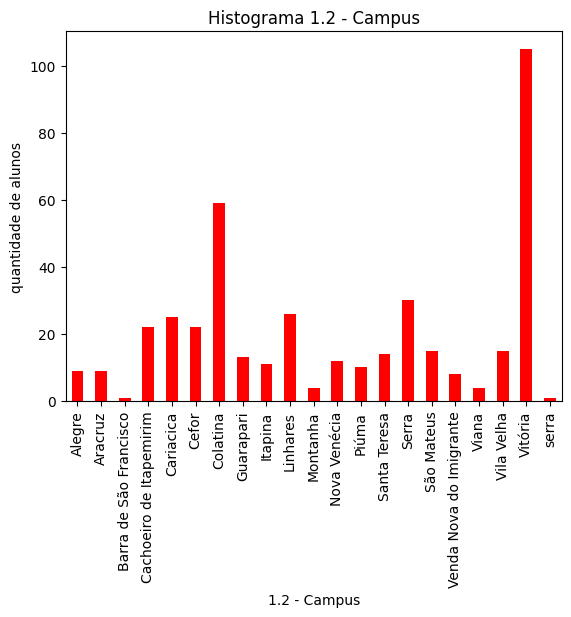

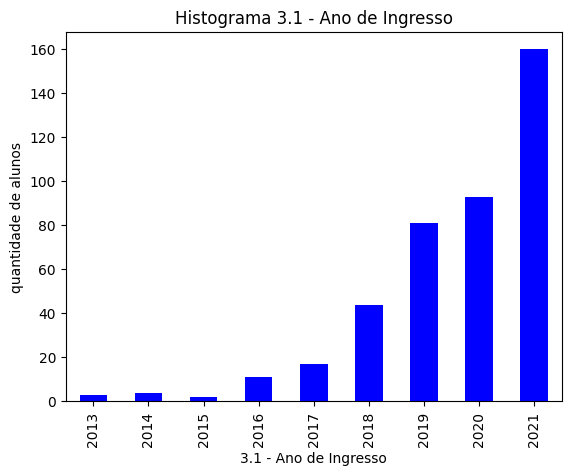

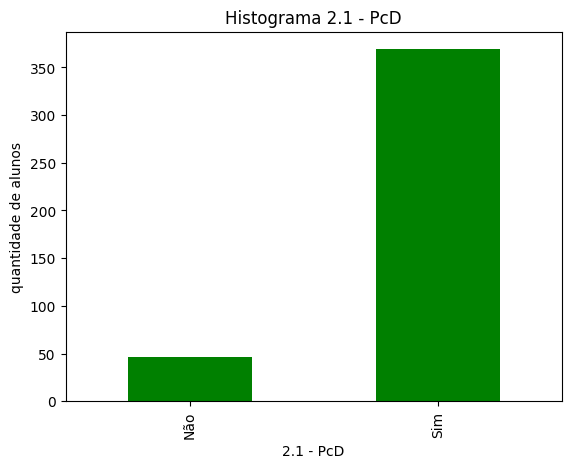

In [30]:
# Graficos preliminares.
metaDados = ["1.2 - Campus", "3.1 - Ano de Ingresso", "2.1 - PcD"]
cores = ["Red", "Blue", "Green"]

for x, cor in zip(metaDados, cores):

    dfGru = df.groupby(x).size()
    dfGru.plot(kind="bar", color=cor)
    
    plt.title(f"Histograma {x}")
    plt.xlabel(f"{x}")
    plt.ylabel("quantidade de alunos")
    plt.show()



Atividade 3 - Experimento sobre as estruturas dos dados e a performance no
tratamento

In [31]:
# gerando chaves aleatorias para as buscas

tamMax: int = len(df)
listaMatriculas: list[str] = []

for i in range(100):
    id = random.randint(0, tamMax-1)
    listaMatriculas.append(df.loc[id, "1.1 - Matricula"])



In [32]:
# busca Linear simples

listaTempos: list[float] = []

for mat in listaMatriculas:
    tempo = time.time()
    df["1.1 - Matricula"] == mat
    listaTempos.append(time.time() - tempo)

print(listaTempos)

[0.0010008811950683594, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0009989738464355469, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0010013580322265625, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0009987354278564453, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.001001596450805664, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.00099945068359375, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.001001119613647461, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [33]:
# Busca Binaria

df_ord = df
df_ord.sort_values(by='1.1 - Matricula', inplace=True)


listaTemposOrd: list[float] = []

for mat in listaMatriculas:
    tempo = time.time()
    df_ord['1.1 - Matricula'].searchsorted(mat)
    listaTemposOrd.append(time.time() - tempo)


print(listaTemposOrd)

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0010004043579101562, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


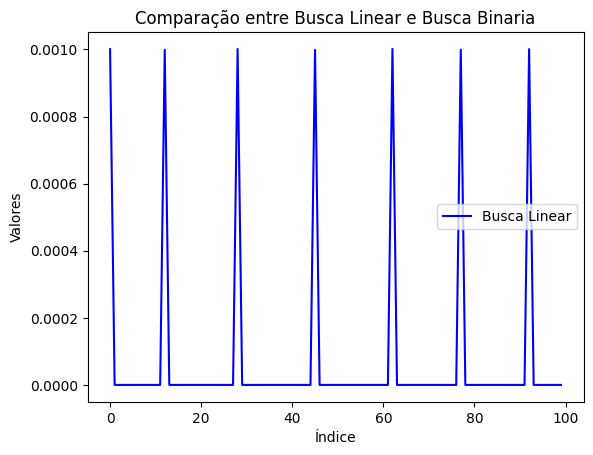

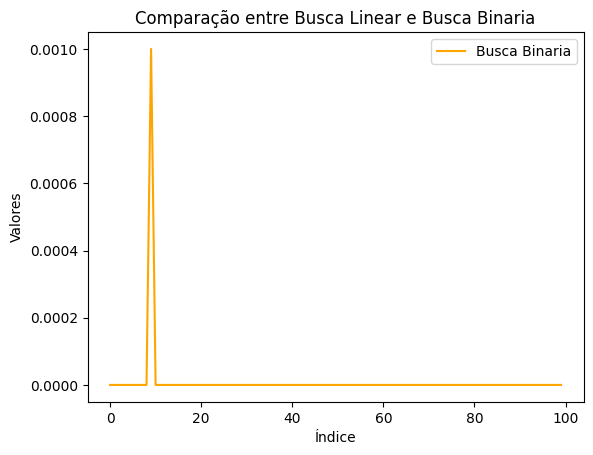

In [34]:
# Comparando as buscas

# Busca Linear
eixo_x = range(0, len(listaTempos))

plt.plot(eixo_x, listaTempos, label='Busca Linear', linestyle='-', color='blue')

plt.xlabel('Índice')
plt.ylabel('Valores')
plt.title('Comparação entre Busca Linear e Busca Binaria')

plt.legend()
plt.show()

# Busca Binaria
eixo_x = range(0, len(listaTemposOrd))

plt.plot(eixo_x, listaTemposOrd, label='Busca Binaria', linestyle='-', color='orange')

plt.xlabel('Índice')
plt.ylabel('Valores')
plt.title('Comparação entre Busca Linear e Busca Binaria')

plt.legend()
plt.show()


Atividade 4a - Construção de gráficos para análise das informações

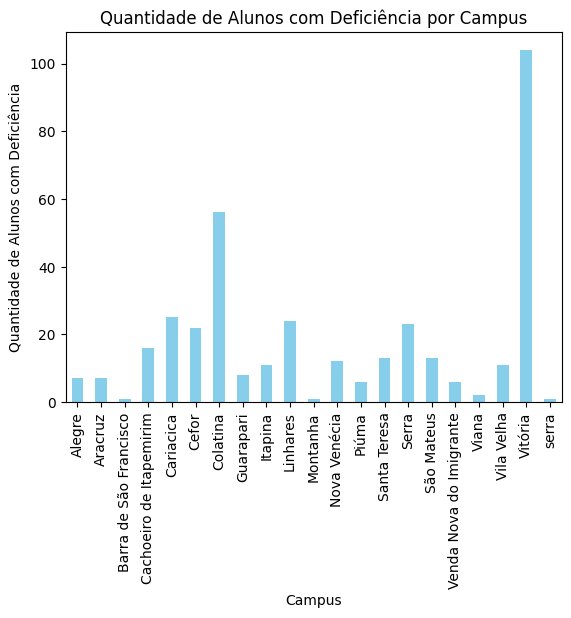

In [35]:
# Filtrar as linhas onde 'PcD' é igual a 'sim'
alunos_com_deficiencia = df[df["2.1 - PcD"] == 'Sim']

# Agrupar por campus e contar a quantidade de alunos com deficiência em cada campus
dados_por_campus = alunos_com_deficiencia.groupby("1.2 - Campus").size()

# Criar o gráfico de barra
dados_por_campus.plot(kind='bar', color='skyblue')
plt.title('Quantidade de Alunos com Deficiência por Campus')
plt.xlabel('Campus')
plt.ylabel('Quantidade de Alunos com Deficiência')
plt.show()

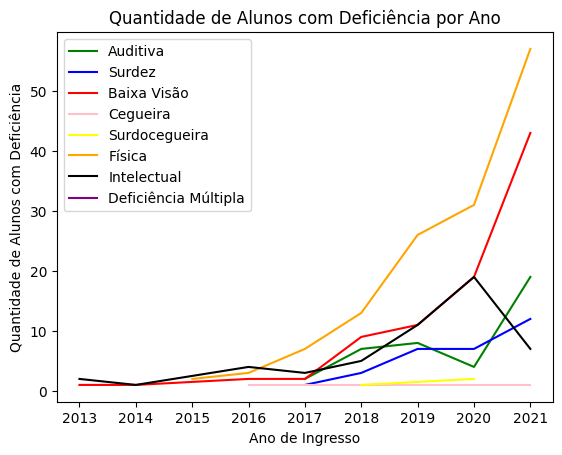

In [36]:
# Filtrar as linhas onde 'PcD' é igual a 'sim'
alunos_com_deficiencia = df[df["2.1 - PcD"] == 'Sim']
listaDef = ["2.1.1 - Auditiva", "2.1.2 - Surdez", "2.1.4 - Baixa Visão","2.1.5 - Cegueira", "2.1.6 - Surdocegueira" , "2.1.7 - Física", "2.1.8 - Intelectual", "2.1.9 - Deficiência Múltipla"]
listaCores = ["Green", "Blue", "Red", "Pink", "Yellow", "Orange", "Black", "Purple"]

tam = len(listaDef)

for i, cor in zip(listaDef, listaCores):
    alunos_com_certa_deficiencia_por_ano = alunos_com_deficiencia[alunos_com_deficiencia[i] == "Sim"]
    dados_por_ano = alunos_com_certa_deficiencia_por_ano.groupby("3.1 - Ano de Ingresso").size()
    
    dados_por_ano.plot(kind='line', color=cor, label = limpa(i))
    


plt.legend()
plt.title('Quantidade de Alunos com Deficiência por Ano')
plt.xlabel('Ano de Ingresso')
plt.ylabel('Quantidade de Alunos com Deficiência')
plt.show()

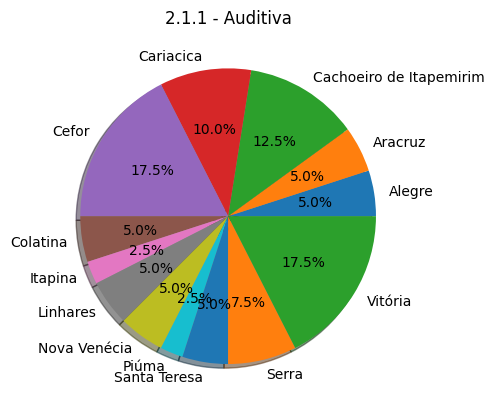

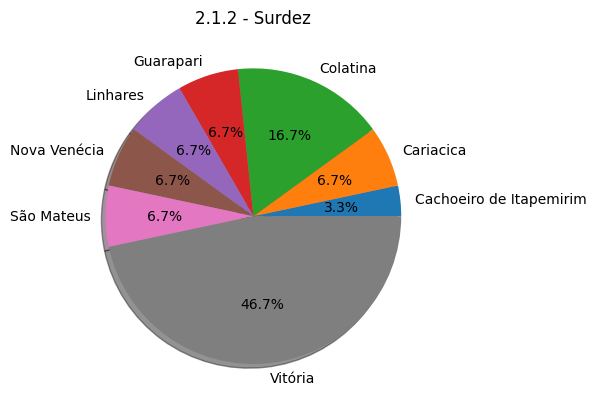

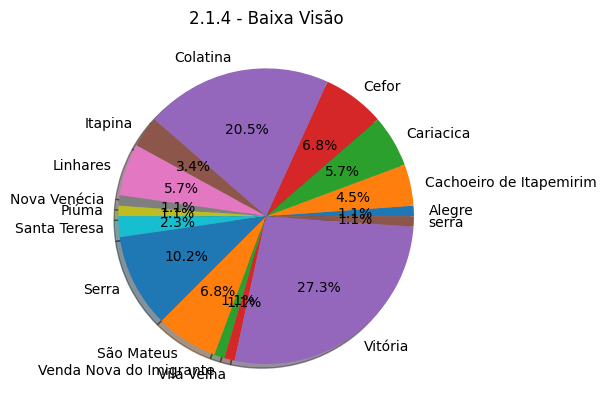

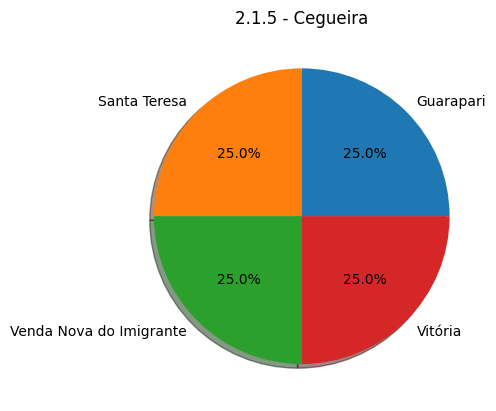

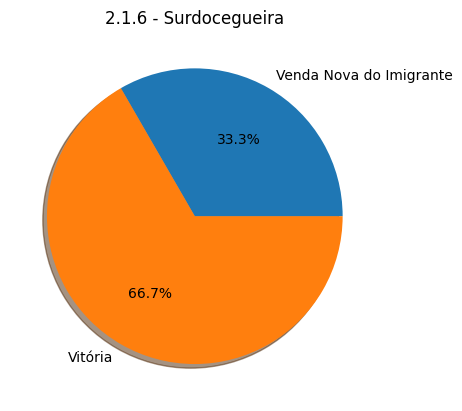

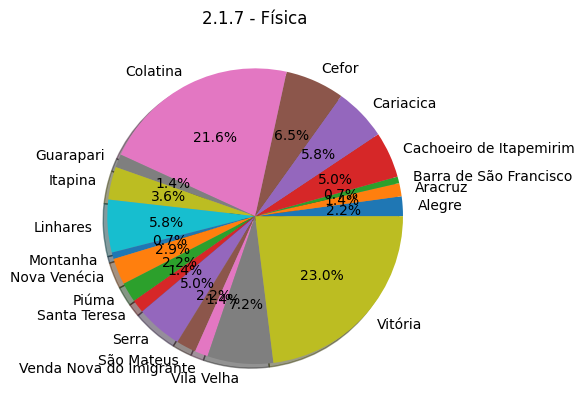

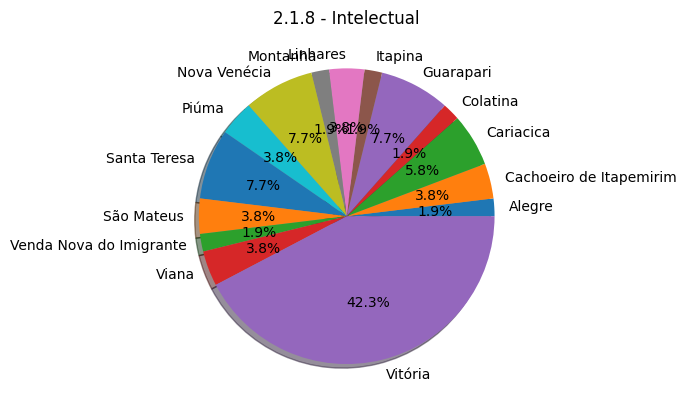

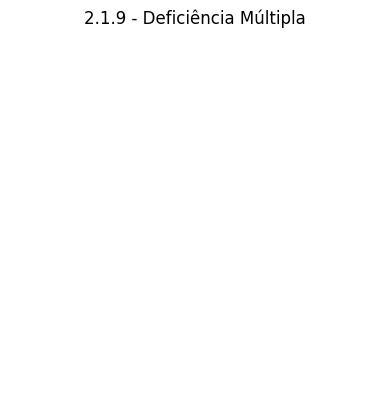

In [37]:
# Filtrar as linhas onde 'PcD' é igual a 'sim'
alunos_com_deficiencia = df[df["2.1 - PcD"] == 'Sim']
listaDef = ["2.1.1 - Auditiva", "2.1.2 - Surdez", "2.1.4 - Baixa Visão","2.1.5 - Cegueira", "2.1.6 - Surdocegueira" , "2.1.7 - Física", "2.1.8 - Intelectual", "2.1.9 - Deficiência Múltipla"]

for i in listaDef:
    alunos_com_certa_deficiencia_por_campus = alunos_com_deficiencia[alunos_com_deficiencia[i] == "Sim"]
    dados_por_campus = alunos_com_certa_deficiencia_por_campus.groupby("1.2 - Campus").size()
    
    dados_por_campus.plot(kind='pie', shadow = True, autopct='%.1f%%')
    plt.title(f"{i}")
    plt.show()
    

Atividade 5 - Discussão sobre estruturas e algoritmos usados

Analise do código do gráfico “Quantidade de alunos com deficiência por ano”

Primeiro o código guarda as informações contidas nas linhas com os dados de um aluno que é pcd, ou seja, a coluna 2.1 - PCD está igual a ‘Sim’, na variável alunos_com_deficiencia.  Depois disso é gerado uma lista contendo o nome de todas as colunas relacionadas a deficiências e outra com as cores que serão usadas no gráfico.

Agora será preciso armazenar todos as linhas sobre alunos com determinada deficiência na variável alunos_com_certa_deficiencia_por_ano. Isso é feito percorrendo a nossa variavel alunos_com_deficiencia e adicionando somente as linhas onde a coluna com o nome da deficiência que estamos analisando no momento seja igual a sim. Para isso eu percorro a minha lista com o nome das colunas relacionadas a tipos de deficiência e filtro o dataset. Depois disso eu filtro a variável alunos_com_certa_deficiencia_por_ano e armazeno os anos de ingresso na variável dados_por_ano. Agora que eu tenho todos os anos de ingresso ligados a um tipo de deficiencia salvos eu posso transformar isso em um gráfico. Após chamar a função plot() o meu código percorre a variável e soma o número de vezes que cada ano se repete para então gerar um gráfico, onde x é igual ao ano e y é igual ao número de alunos com esse tipo de deficiência. Esse processo se repete até conseguirmos gerar um gráfico para cada conjunto de dados, que pode então ser imprimidos juntos para melhorar a visualização dos dados.
